<a href="https://colab.research.google.com/github/ishwaryac20-prog/US_Healthcare_Claims_Denials_-_Revenue_Analytics_Using_Python/blob/main/US_Healthcare_Claims_Denials_Revenue_Analytics_Using_Python_Final_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

 # **US Healthcare Claims Denials-Revenue Analytics Using Python**


# **Problem statment:**


To analyze US healthcare claims data to identify claim approval, rejection, and pending patterns, understand major denial reasons, and identify payers, procedures, facilities, providers, and submission methods associated with claim denials and payment delays.

# **Outcome:**

To identify the main reasons for claim denials and payment delays and find the payors, procedures, facilities, and providers with the highest claim issues, helping improve the overall claim payment process.

# **Domain:**
US Healthcare Claims Denial


# **Dataset** **Information:**

**Source:** [Hugging Face](https://huggingface.co/)

**Dataset Link:** [Medical Billing RCM Dataset](https://huggingface.co/datasets/Abdoo0010/Medical_Billing_RCM)

**Year / Timeline:** 2023 – 2025

**Number of Rows:** 1,00,000

**Number of Columns:** 30

## **Dataset Column / Features Description:**

| Column Name | Description |
|---|---|
| BillingID | Unique ID for each billing record |
| SubmissionDate | Date when the claim was submitted |
| RandomNote | Note associated with the claim |
| ConstantFlag | Reference/flag field |
| UnrelatedMetric | Additional numerical metric |
| EmptyColumn | Empty or unused column |
| ProcedureID | Unique ID of the medical procedure |
| FacilityID | Unique ID of the healthcare facility |
| InsuranceID | Unique ID of the insurance company |
| PatientID | Unique ID of the patient |
| PhysicianID | Unique ID of the physician |
| ClaimMetaID | Claim metadata identifier |
| BilledAmount | Amount billed for the medical service |
| ApprovalStatus | Status of the claim such as Approved, Rejected, or Pending |
| RejectionReason | Reason for claim rejection or denial |
| FinalPaymentDate | Date when the final payment was received |
| CollectedAmount | Amount collected for the claim |
| PaymentChannel | Channel or method used for payment |
| ClaimStatus | Current status of the claim |
| Age | Age of the patient |
| Gender | Gender of the patient |
| Location | Patient location/state |
| InsuranceCompany | Name of the insurance company/payer |
| ProcedureDesc | Description of the medical procedure |
| FacilityName | Name of the healthcare facility |
| PhysicianName | Name of the physician |
| ClaimType | Type of healthcare claim |
| ClaimChannel | Channel/method through which the claim was submitted |
| ReferralSource | Source of patient referral |
| ServiceLine | Healthcare service category |

# **Dataset Loading and Initial Overview:**

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
url = "https://github.com/ishwaryac20-prog/US_Healthcare_Claims_Denials_-_Revenue_Analytics_Using_Python/raw/d4c52bc53fa690c21bfa83db00fd9b57b910f092/Raw%20Data%20Healthcare%20Claims.xlsx"

df = pd.read_excel(url)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

Dataset loaded successfully!
Dataset shape: (100000, 30)


In [ ]:
display(df.head())

,BillingID,SubmissionDate,RandomNote,ConstantFlag,UnrelatedMetric,EmptyColumn,ProcedureID,FacilityID,InsuranceID,PatientID,...,Gender,Location,InsuranceCompany,ProcedureDesc,FacilityName,PhysicianName,ClaimType,ClaimChannel,ReferralSource,ServiceLine
0,352676,2024-03-31,Patient responsibility not collected,UNUSED,97.894898,0,5,1,1,7980,...,Male,Florida,Aetna,Surgery,General Hospital,Jordan Henry,Emergency,Online,Referral,Surgery
1,810635,2023-02-09,Authorization not obtained,UNUSED,45.000336,0,4,1,2,4418,...,Female,Texas,Cigna,Blood Test,General Hospital,Randall Whitaker,Emergency,Mail,Walk-in,Primary Care
2,629433,2025-02-07,Patient responsibility not collected,UNUSED,15.578144,0,2,4,2,6407,...,Male,Pennsylvania,Cigna,X-Ray,Metro Hospital,Jennifer Hill,Outpatient,Online,Walk-in,Primary Care
3,15808,2024-05-05,Patient responsibility not collected,UNUSED,29.258190,0,4,2,1,6431,...,Male,Texas,Aetna,Blood Test,City Clinic,Michael Roberts,Inpatient,EDI,Walk-in,Primary Care
4,551247,2025-03-11,Deductible not met by patient,UNUSED,87.454297,0,1,2,1,8773,...,Male,California,Aetna,MRI,City Clinic,Meghan Watson,Emergency,EDI,Referral,Primary Care


In [ ]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Rows: 100000
Columns: 30


In [ ]:
df.dtypes

,0
BillingID,int64
SubmissionDate,datetime64[ns]
RandomNote,object
ConstantFlag,object
UnrelatedMetric,float64
EmptyColumn,int64
ProcedureID,int64
FacilityID,int64
InsuranceID,int64
PatientID,int64


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 30 columns):
 #   Column            Non-Null Count   Dtype         
---  ------            --------------   -----         
 0   BillingID         100000 non-null  int64         
 1   SubmissionDate    100000 non-null  datetime64[ns]
 2   RandomNote        100000 non-null  object        
 3   ConstantFlag      100000 non-null  object        
 4   UnrelatedMetric   100000 non-null  float64       
 5   EmptyColumn       100000 non-null  int64         
 6   ProcedureID       100000 non-null  int64         
 7   FacilityID        100000 non-null  int64         
 8   InsuranceID       100000 non-null  int64         
 9   PatientID         100000 non-null  int64         
 10  PhysicianID       100000 non-null  int64         
 11  ClaimMetaID       100000 non-null  int64         
 12  BilledAmount      100000 non-null  float64       
 13  ApprovalStatus    100000 non-null  object        
 14  Rejec

In [ ]:
df.describe()

,BillingID,SubmissionDate,UnrelatedMetric,EmptyColumn,ProcedureID,FacilityID,InsuranceID,PatientID,PhysicianID,ClaimMetaID,BilledAmount,CollectedAmount,Age
count,100000.000000,100000,100000.000000,100000.0,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.00000,100000.000000,100000.000000,100000.000000
mean,500218.320080,2024-06-16 14:34:56.640000256,50.069533,0.0,3.054230,2.155740,2.642890,4998.187070,536.137690,50.48528,769.699591,482.952438,44.050280
min,10.000000,2023-01-01 00:00:00,0.000634,0.0,1.000000,1.000000,1.000000,1.000000,3.000000,1.00000,-9163.990000,0.000000,0.000000
25%,250554.000000,2023-12-16 00:00:00,25.174770,0.0,2.000000,1.000000,1.000000,2506.000000,291.000000,25.00000,100.000000,0.000000,30.000000
50%,500474.000000,2024-07-20 00:00:00,50.115814,0.0,3.000000,2.000000,3.000000,4998.000000,596.000000,50.00000,147.650000,92.790000,44.000000
75%,749880.500000,2025-01-10 00:00:00,75.001003,0.0,4.000000,3.000000,3.000000,7500.000000,788.000000,75.00000,551.005000,220.602500,58.000000
max,999980.000000,2025-06-06 00:00:00,99.999132,0.0,5.000000,4.000000,5.000000,10000.000000,990.000000,100.00000,10000.000000,9910.040000,100.000000
std,288124.206101,NaN,28.832264,0.0,1.204726,1.152501,1.269306,2883.876183,295.859301,28.88222,1550.113408,1164.296067,20.175132


**Observations:**

- **BilledAmount:** Mean is 769.70 and median is 147.65. The maximum is 10,000, suggesting a right-skewed distribution and potential high-value outliers.
- **CollectedAmount:** Mean is 482.95 and median is 92.79. The maximum is 9,910.04, suggesting right skew and possible outliers.
- **Age:** Mean is 44.05 and median is 44. Age ranges from 0 to 100, so unusual values should be checked.
- **Negative BilledAmount:** The minimum is -9,163.99, indicating negative billed amounts that require further investigation.
- **EmptyColumn:** All values are zero, so this column is not useful for analysis.
- **UnrelatedMetric:** This column appears unrelated to the claims analysis and can be removed.

## **Data Cleaning and Pre-processing**

**1. Check missing values**
- Check missing values before cleaning.
- Missing payment dates will be reviewed after converting the date column.

In [ ]:
print(df.isnull().sum())


BillingID           0
SubmissionDate      0
RandomNote          0
ConstantFlag        0
UnrelatedMetric     0
EmptyColumn         0
ProcedureID         0
FacilityID          0
InsuranceID         0
PatientID           0
PhysicianID         0
ClaimMetaID         0
BilledAmount        0
ApprovalStatus      0
RejectionReason     0
FinalPaymentDate    0
CollectedAmount     0
PaymentChannel      0
ClaimStatus         0
Age                 0
Gender              0
Location            0
InsuranceCompany    0
ProcedureDesc       0
FacilityName        0
PhysicianName       0
ClaimType           0
ClaimChannel        0
ReferralSource      0
ServiceLine         0
dtype: int64


**2. Remove exact duplicate rows**
- Remove complete duplicate records only.
- Do not remove records just because `BillingID` repeats unless the dataset confirms those are duplicates.

In [ ]:
df = df.drop_duplicates()

print("Dataset shape:", df.shape)
print("Exact duplicate rows remaining:", df.duplicated().sum())
print("Duplicate BillingIDs:", df["BillingID"].duplicated().sum())


Dataset shape: (99906, 30)
Exact duplicate rows remaining: 0
Duplicate BillingIDs: 3


**3. Remove unnecessary columns**
- Remove columns that are not useful for claims analysis.

In [ ]:
df = df.drop(
    columns=["RandomNote", "ConstantFlag", "EmptyColumn", "UnrelatedMetric"],
    errors="ignore"
)

print("Dataset shape after removing unnecessary columns:", df.shape)


Dataset shape after removing unnecessary columns: (99906, 26)


**4. Clean rejection reasons**
- Replace `0` placeholders with `Not Applicable`.
- Review the rejection-reason distribution.

In [ ]:
df["RejectionReason"] = df["RejectionReason"].replace(0, "Not Applicable")
display(df["RejectionReason"].value_counts().head(15))


,count
RejectionReason,
Not Applicable,84632
Invalid Insurance,3037
Authorization Required,3013
Missing Documentation,3006
Incorrect Patient Info,3003
Procedure Not Covered,2953
Cheque Processing Delay,262


**5. Clean payment channels**
- Replace `0` placeholders with `Not Applicable`.
- Review the payment-channel distribution.

In [ ]:
df["PaymentChannel"] = df["PaymentChannel"].replace(0, "Not Applicable")
display(df["PaymentChannel"].value_counts())


,count
PaymentChannel,
Not Applicable,26200
Online Portal,25940
Credit Card,22060
Bank Transfer,18517
Cheque,7189


**6. Handle unknown locations**
- Replace `0` placeholders with `Unknown`.
- Review location counts.

In [ ]:
df["Location"] = df["Location"].replace(0, "Unknown")
display(df["Location"].value_counts().head(15))


,count
Location,
Georgia,19394
California,17610
Texas,15355
Florida,11830
New York,9938
Pennsylvania,8735
Illinois,8331
Ohio,7712
Unknown,1001


**7. Identify negative billed amounts**
- Flag negative billed amounts for review.
- Keep the original amounts; do not automatically delete them.

In [ ]:
df["NegativeBilledAmount"] = df["BilledAmount"] < 0

print("Negative billed amount records:", df["NegativeBilledAmount"].sum())
display(df.loc[df["NegativeBilledAmount"], ["BillingID", "BilledAmount"]].head())


Negative billed amount records: 1001


,BillingID,BilledAmount
81,889305,-207.27
155,265139,-1501.04
257,285130,-384.18
283,983398,-100.00
317,308193,-143.11


**8. Convert payment date format**
- Convert `FinalPaymentDate` to datetime.
- Invalid or unavailable dates become `NaT` and are not filled with invented values.

In [ ]:
df["SubmissionDate"] = pd.to_datetime(df["SubmissionDate"], errors="coerce")
df["FinalPaymentDate"] = pd.to_datetime(df["FinalPaymentDate"], errors="coerce")

print("SubmissionDate data type:", df["SubmissionDate"].dtype)
print("FinalPaymentDate data type:", df["FinalPaymentDate"].dtype)
print("Missing payment dates:", df["FinalPaymentDate"].isna().sum())


SubmissionDate data type: datetime64[ns]
FinalPaymentDate data type: datetime64[ns]
Missing payment dates: 26962


**9. Identify missing payment dates**
- Create a flag for records without a final payment date.

In [ ]:
df["MissingPaymentDate"] = df["FinalPaymentDate"].isna()
display(df["MissingPaymentDate"].value_counts())


,count
MissingPaymentDate,
False,72944
True,26962


**10. Calculate payment turnaround days**
- Calculate the number of days between submission and final payment.
- Missing dates remain missing.

In [ ]:
df["PaymentTurnaroundDays"] = (
    df["FinalPaymentDate"] - df["SubmissionDate"]
).dt.days

display(df["PaymentTurnaroundDays"].describe())


,PaymentTurnaroundDays
count,72944.000000
mean,26.149745
std,16.134430
min,5.000000
25%,14.000000
50%,22.000000
75%,34.000000
max,96.000000


**11. Verify missing values after cleaning**
- Review missing values by column.
- Missing payment dates and turnaround days are expected when payment dates are unavailable.

In [ ]:
missing_values = df.isna().sum()
display(missing_values[missing_values > 0])


,0
FinalPaymentDate,26962
PaymentTurnaroundDays,26962


**12. Check age values**
- Review the age distribution and check for values outside the 0–100 range.

In [ ]:
display(df["Age"].describe())
print("Age values below 0 or above 100:", ((df["Age"] < 0) | (df["Age"] > 100)).sum())


,Age
count,99906.000000
mean,44.053690
std,20.175297
min,0.000000
25%,30.000000
50%,44.000000
75%,58.000000
max,100.000000


Age values below 0 or above 100: 0


**13. Check collected amounts**
- Check whether any collected amounts are negative.

In [ ]:
print("Negative collected amounts:", (df["CollectedAmount"] < 0).sum())


Negative collected amounts: 0


**14.Outlier Detection Using IQR Method**

In [ ]:
cols = ["BilledAmount", "CollectedAmount", "PaymentTurnaroundDays", "Age"]

for col in cols:

    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    count = ((df[col] < lower) | (df[col] > upper)).sum()

    print(col, "- Outliers:", count)

BilledAmount - Outliers: 14902
CollectedAmount - Outliers: 15798
PaymentTurnaroundDays - Outliers: 2104
Age - Outliers: 0


In [ ]:
df_clean = df.copy()

print("Original dataset shape:", df.shape)
print("Dataset for cleaning:", df_clean.shape)


Original dataset shape: (99906, 29)
Dataset for cleaning: (99906, 29)


**Ouliers in BilledAmount**

In [ ]:
Q1 = df_clean["BilledAmount"].quantile(0.25)
Q3 = df_clean["BilledAmount"].quantile(0.75)
IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

print("Lower limit:", lower)
print("Upper limit:", upper)

df_clean["BilledAmount"] = df_clean["BilledAmount"].clip(
    lower=lower, upper=upper
)

Lower limit: -576.6012499999999
Upper limit: 1227.6687499999998


**Outliers in CollectedAmount**

In [ ]:
Q1_collected = df_clean["CollectedAmount"].quantile(0.25)
Q3_collected = df_clean["CollectedAmount"].quantile(0.75)
IQR_collected = Q3_collected - Q1_collected

lower_collected = Q1_collected - 1.5 * IQR_collected
upper_collected = Q3_collected + 1.5 * IQR_collected

print("Lower limit:", lower_collected)
print("Upper limit:", upper_collected)

df_clean["CollectedAmount"] = df_clean["CollectedAmount"].clip(
    lower=lower_collected, upper=upper_collected
)


Lower limit: -331.0575
Upper limit: 551.7625


**Outliers in PaymentTurnAroundDays**

In [ ]:
Q1_days = df_clean["PaymentTurnaroundDays"].quantile(0.25)
Q3_days = df_clean["PaymentTurnaroundDays"].quantile(0.75)
IQR_days = Q3_days - Q1_days

lower_days = Q1_days - 1.5 * IQR_days
upper_days = Q3_days + 1.5 * IQR_days

print("Lower limit:", lower_days)
print("Upper limit:", upper_days)

df_clean["PaymentTurnaroundDays"] = df_clean[
    "PaymentTurnaroundDays"
].clip(lower=lower_days, upper=upper_days)

Lower limit: -16.0
Upper limit: 64.0


**Outlier Cleaning – Observations**
1. Outliers were identified using the IQR method.
2. Outliers were found in BilledAmount, CollectedAmount, and PaymentTurnaroundDays.
3. No outliers were detected in Age.
4. Capping was applied to the identified numerical columns.
5. After capping, no outliers remained outside the IQR limits.

**Skewness Analysis**

In [ ]:
numeric_cols = df_clean.select_dtypes(include="number").columns

skewness = df_clean[numeric_cols].skew().sort_values(
    ascending=False
)

display(skewness.to_frame(name="Skewness"))


,Skewness
BilledAmount,1.181017
CollectedAmount,1.077063
PaymentTurnaroundDays,0.871886
FacilityID,0.485515
InsuranceID,0.230722
Age,0.008654
ClaimMetaID,0.000361
PatientID,-0.001133
BillingID,-0.003436
ProcedureID,-0.101075


**Observations**
1. BilledAmount (1.18) showed the highest positive skewness.
2. CollectedAmount (1.08) and PaymentTurnaroundDays (0.87) also showed positive skewness.
3. Age (0.009) showed an almost symmetrical distribution.
4. ProcedureID and PhysicianID showed slight negative skewness.
5. Most numerical columns showed low skewness, but ID columns are identifiers and should not be interpreted as continuous numerical data.

In [ ]:
df_clean["SubmissionYear"] = df_clean["SubmissionDate"].dt.year
df_clean["SubmissionMonth"] = df_clean["SubmissionDate"].dt.month

# **Exploratory Data Analysis (EDA) and Visualizations**

**Univariate Analysis**

**Claim Approval Status Distribution**

---



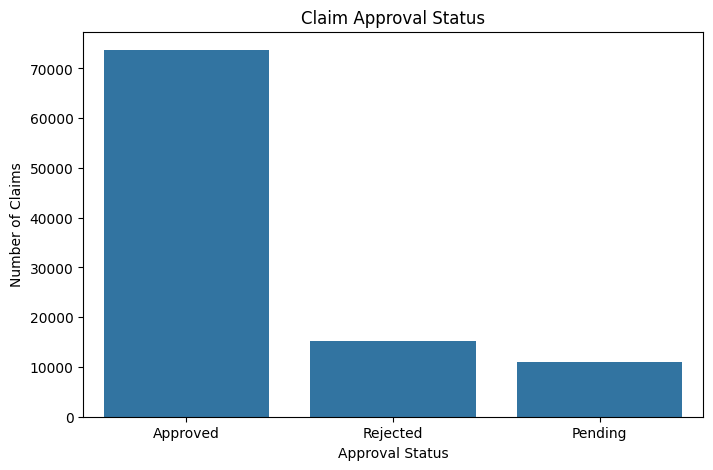

In [ ]:
plt.figure(figsize=(8, 5))
sns.countplot(data=df_clean, x="ApprovalStatus")
plt.title("Claim Approval Status")
plt.xlabel("Approval Status")
plt.ylabel("Number of Claims")
plt.show()

**Rejection Reason Distribution**

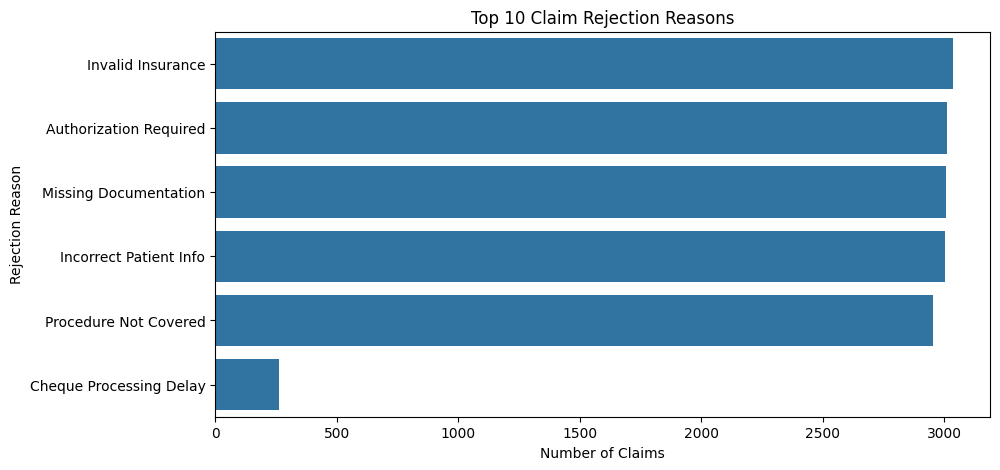

In [ ]:
rejected = df_clean[df_clean["ApprovalStatus"] == "Rejected"]

plt.figure(figsize=(10, 5))
sns.countplot(
    data=rejected,
    y="RejectionReason",
    order=rejected["RejectionReason"].value_counts().head(10).index
)
plt.title("Top 10 Claim Rejection Reasons")
plt.xlabel("Number of Claims")
plt.ylabel("Rejection Reason")
plt.show()

**Billed Amount Distribution**

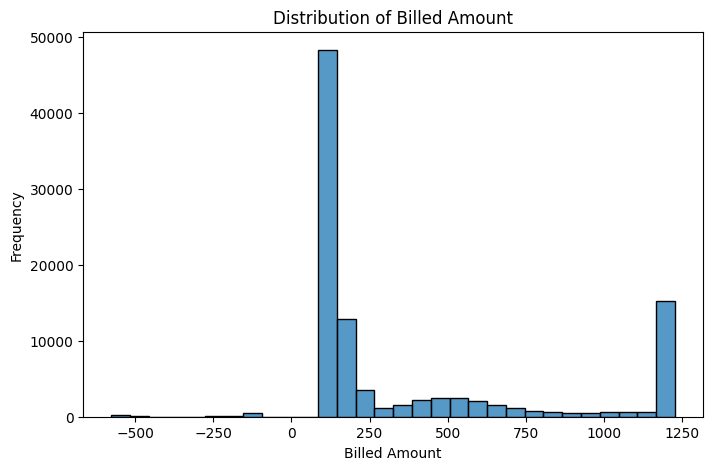

In [ ]:
plt.figure(figsize=(8, 5))
sns.histplot(data=df_clean, x="BilledAmount", bins=30)
plt.title("Distribution of Billed Amount")
plt.xlabel("Billed Amount")
plt.ylabel("Frequency")
plt.show()

**Billed Amount Distribution (KDE)**

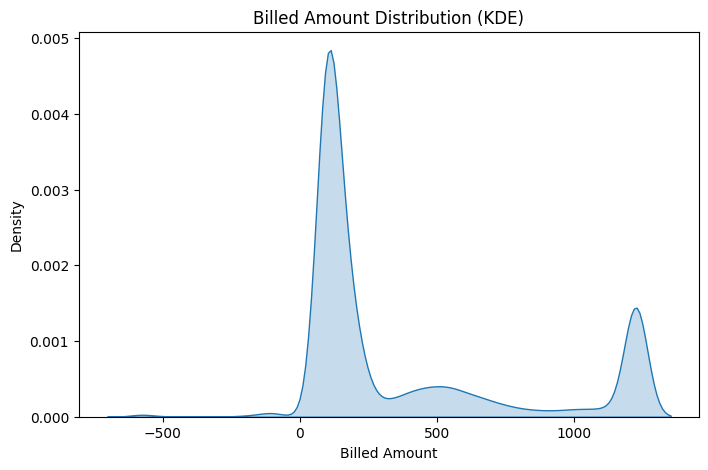

In [ ]:
plt.figure(figsize=(8, 5))
sns.kdeplot(data=df_clean, x="BilledAmount", fill=True)
plt.title("Billed Amount Distribution (KDE)")
plt.xlabel("Billed Amount")
plt.ylabel("Density")
plt.show()

**Insights**
- The distribution has a prominent peak in the lower billed amount range.
- A smaller peak appears in the higher amount range.
- The distribution is positively skewed.

**Interpretation of the chart**

The KDE plot shows the density distribution of BilledAmount.

It helps identify the ranges where claim amounts are concentrated and supports the skewness analysis performed earlier.

**Collected Amount Distribution**

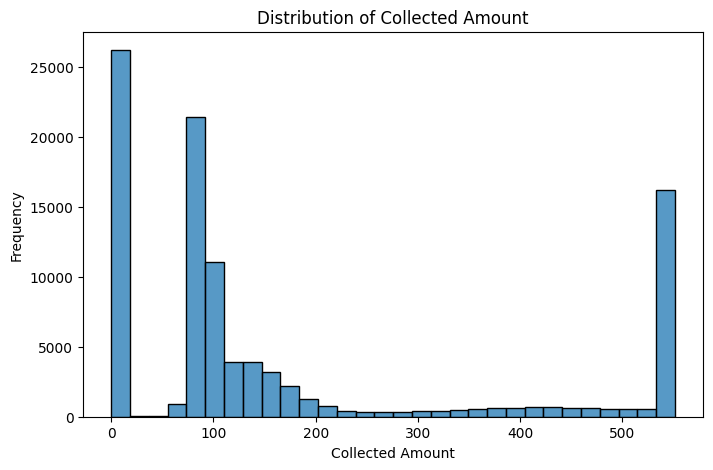

In [ ]:
plt.figure(figsize=(8, 5))
sns.histplot(data=df_clean, x="CollectedAmount", bins=30)
plt.title("Distribution of Collected Amount")
plt.xlabel("Collected Amount")
plt.ylabel("Frequency")
plt.show()

**Payment Turnaround Days Distribution**

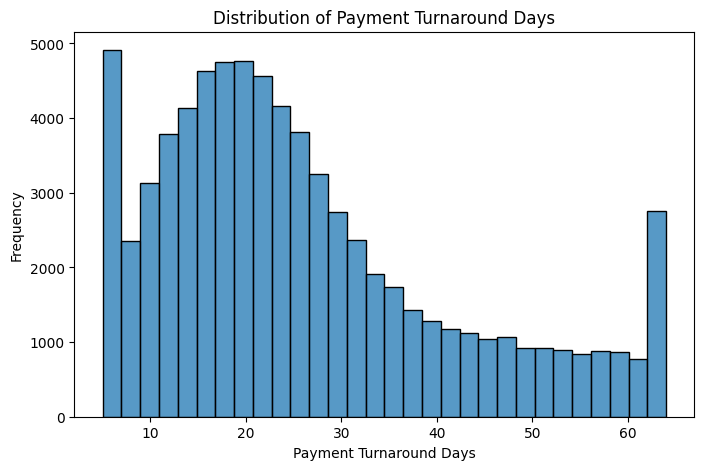

In [ ]:
plt.figure(figsize=(8, 5))
sns.histplot(data=df_clean, x="PaymentTurnaroundDays", bins=30)
plt.title("Distribution of Payment Turnaround Days")
plt.xlabel("Payment Turnaround Days")
plt.ylabel("Frequency")
plt.show()

**Age Distribution**

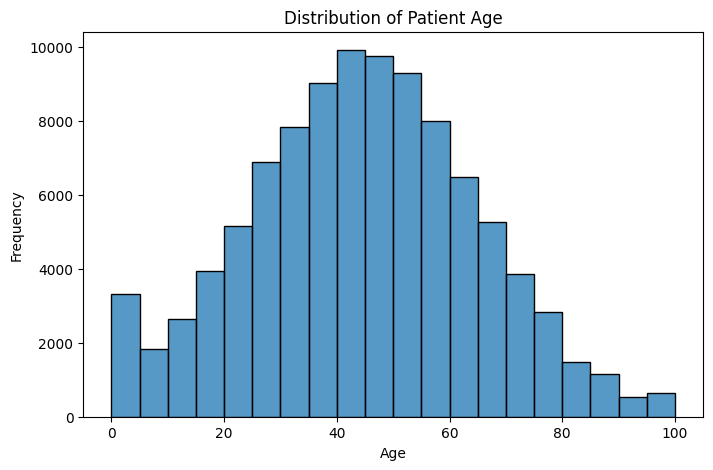

In [ ]:
plt.figure(figsize=(8, 5))
sns.histplot(data=df_clean, x="Age", bins=20)
plt.title("Distribution of Patient Age")
plt.xlabel("Age")
plt.ylabel("Frequency")
plt.show()

**Billed Amount Box Plot**

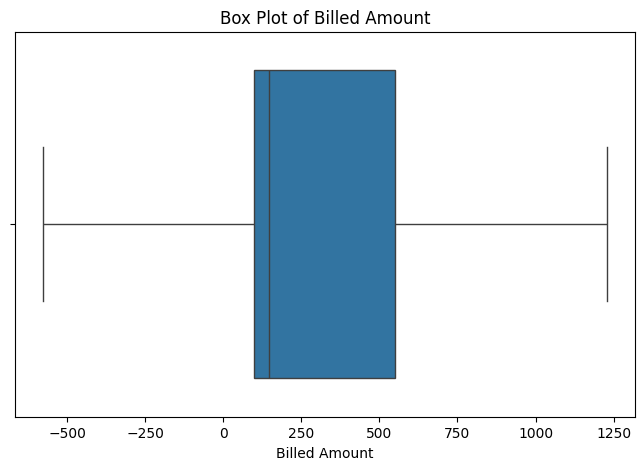

In [ ]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df_clean, x="BilledAmount")
plt.title("Box Plot of Billed Amount")
plt.xlabel("Billed Amount")
plt.show()

**Collected Amount Box Plot**

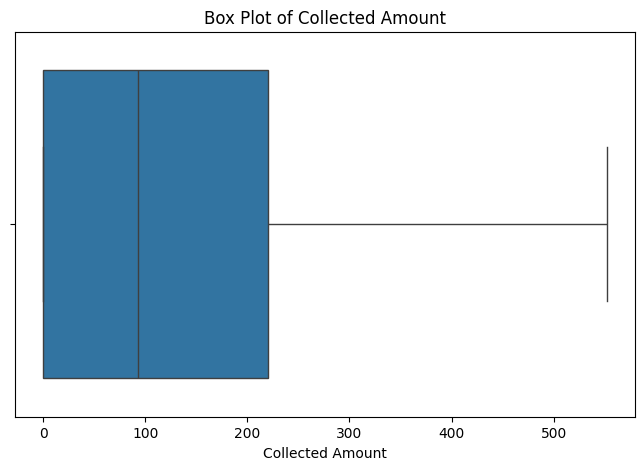

In [ ]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df_clean, x="CollectedAmount")
plt.title("Box Plot of Collected Amount")
plt.xlabel("Collected Amount")
plt.show()

**Payment Turnaround Days Box Plot**

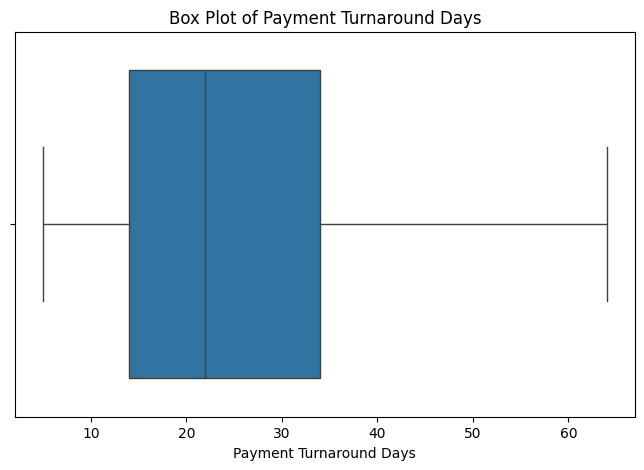

In [ ]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df_clean, x="PaymentTurnaroundDays")
plt.title("Box Plot of Payment Turnaround Days")
plt.xlabel("Payment Turnaround Days")
plt.show()

In [ ]:
columns = [
    "BilledAmount",
    "CollectedAmount",
    "PaymentTurnaroundDays",
    "Age"
]

summary = pd.DataFrame({
    "Skewness": df_clean[columns].skew(),
    "Kurtosis": df_clean[columns].kurt()
})

print(summary.round(2))

                       Skewness  Kurtosis
BilledAmount               1.18     -0.10
CollectedAmount            1.08     -0.41
PaymentTurnaroundDays      0.87     -0.04
Age                        0.01     -0.27


**Skewness Comparison chart**

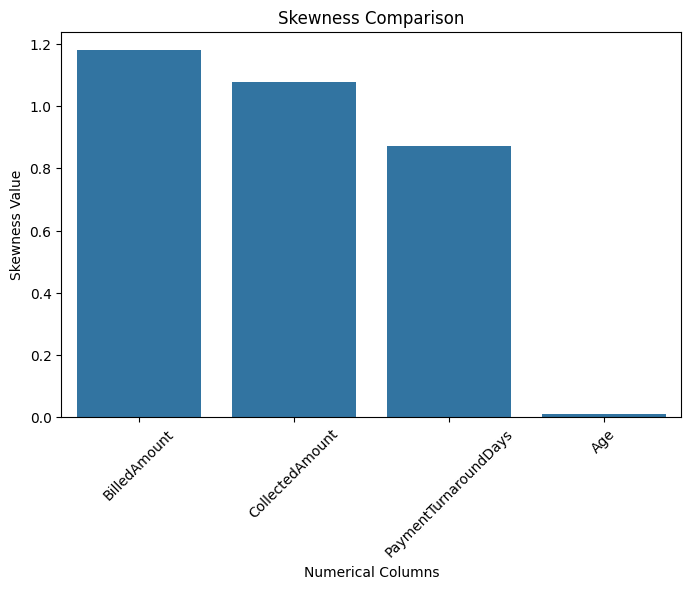

In [ ]:
plt.figure(figsize=(8, 5))
sns.barplot(x=summary.index, y=summary["Skewness"])
plt.title("Skewness Comparison")
plt.xlabel("Numerical Columns")
plt.ylabel("Skewness Value")
plt.xticks(rotation=45)
plt.show()

**Insights**

- BilledAmount has the highest positive skewness among the four numerical variables.
- CollectedAmount and PaymentTurnaroundDays also show positive skewness.
- Age has skewness close to zero.

**Interpretation of the chart**

The chart compares the skewness of BilledAmount, CollectedAmount, PaymentTurnaroundDays, and Age.

The positive values indicate right-skewed distributions, while Age is relatively more symmetrical.

 **Kurtosis Comparison chart**

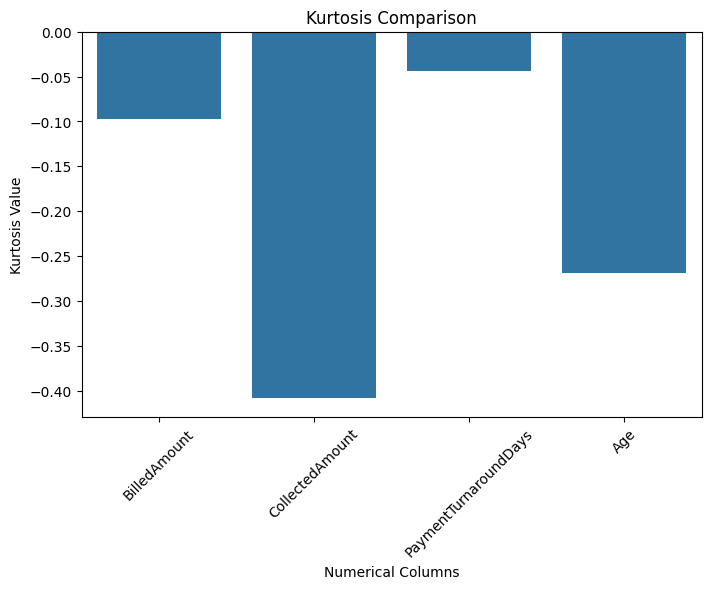

In [ ]:
plt.figure(figsize=(8, 5))
sns.barplot(x=summary.index, y=summary["Kurtosis"])
plt.title("Kurtosis Comparison")
plt.xlabel("Numerical Columns")
plt.ylabel("Kurtosis Value")
plt.xticks(rotation=45)
plt.show()

**Insights**
- All four numerical variables have slightly negative excess kurtosis.
- CollectedAmount has the lowest kurtosis value.
- PaymentTurnaroundDays has a kurtosis value closest to zero.

**Interpretation of the chart**

The chart compares the kurtosis values of the selected numerical variables.

The negative values indicate distributions with lower excess kurtosis than a normal distribution.

Kurtosis alone does not confirm whether outliers are present.

# **Bivariate Analysis**

**Average Collected Amount by Approval Status**

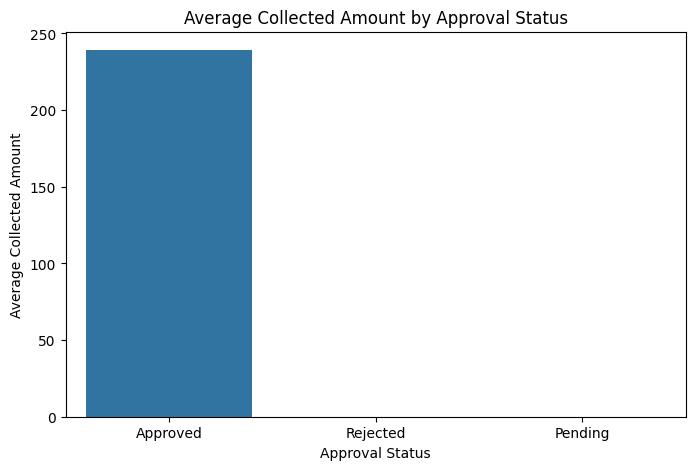

In [ ]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=df_clean,
    x="ApprovalStatus",
    y="CollectedAmount",
    errorbar=None
)

plt.title("Average Collected Amount by Approval Status")
plt.xlabel("Approval Status")
plt.ylabel("Average Collected Amount")
plt.show()

**Insights**
- Approved claims have an average collected amount of approximately 239.20.
- Pending and Rejected claims have an average collected amount of 0.
- Approved claims show higher collection amounts compared to Pending and Rejected claims.

**Interpretation of the chart**

The bar chart compares the average collected amount across different claim approval statuses.

Approved claims show a positive average collected amount, while Pending and Rejected claims show zero in this dataset.

This analysis helps understand the relationship between claim approval status and payment collection.

**Billed Amount vs Collected Amount**

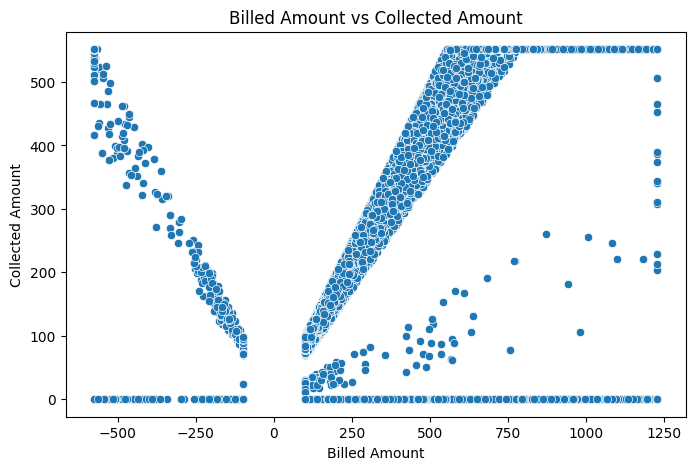

In [ ]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df_clean,
    x="BilledAmount",
    y="CollectedAmount"
)

plt.title("Billed Amount vs Collected Amount")
plt.xlabel("Billed Amount")
plt.ylabel("Collected Amount")
plt.show()

**Insights**

Billed and collected amounts show a moderate positive correlation of 0.63.

Higher billed amounts generally tend to have higher collected amounts.

**Interpretation of the chart**

The scatter plot shows the relationship between billed and collected amounts. It helps understand how claim billing relates to payment collection.

**Claim Status vs Insurance Company**

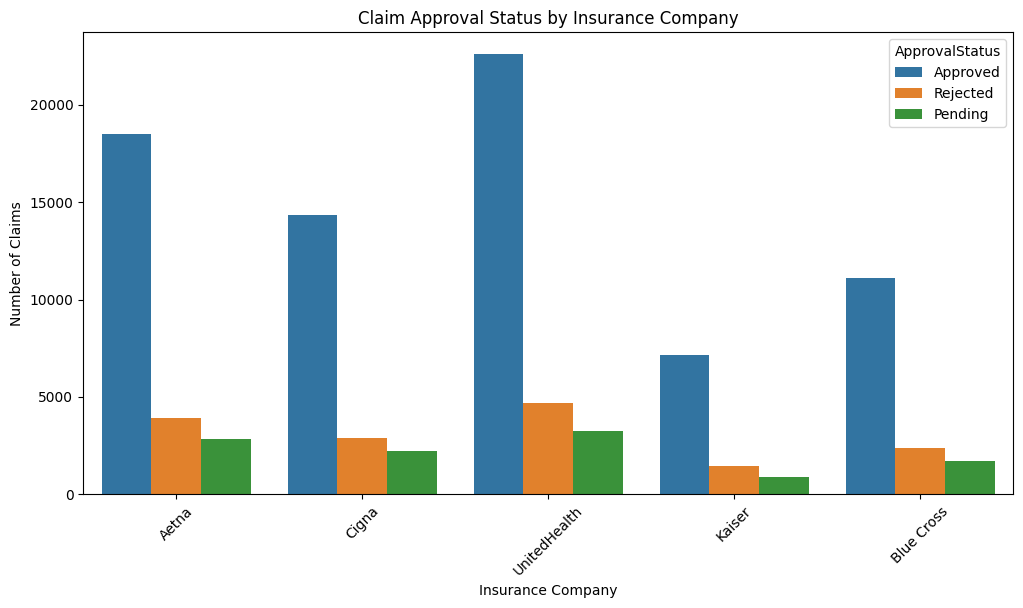

In [ ]:
plt.figure(figsize=(12, 6))

sns.countplot(
    data=df_clean,
    x="InsuranceCompany",
    hue="ApprovalStatus"
)

plt.title("Claim Approval Status by Insurance Company")
plt.xlabel("Insurance Company")
plt.ylabel("Number of Claims")
plt.xticks(rotation=45)
plt.show()

**Insights**
- Claim approval status varies across insurance companies.
- Approved claims are higher in count than Pending and Rejected claims across the insurance companies.

**Interpretation of the chart**

The count plot compares claim approval statuses across insurance companies.

It helps identify differences in Approved, Pending, and Rejected claim counts among insurers.


**Claim Channel vs Approval Status**

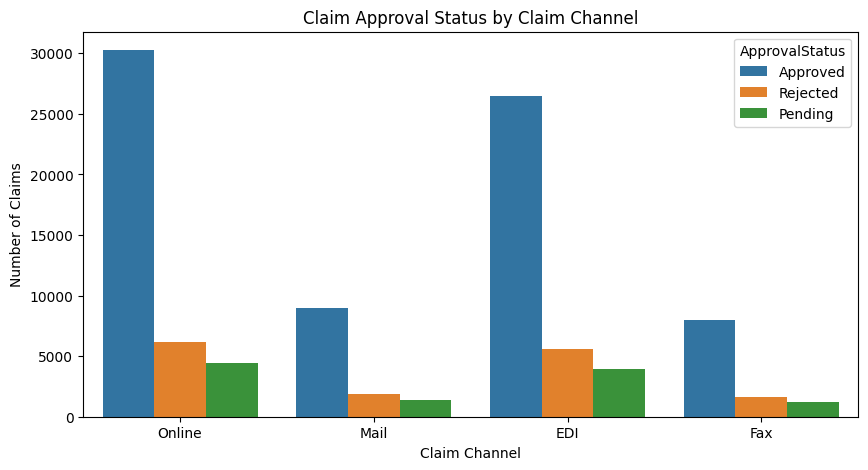

In [ ]:
plt.figure(figsize=(10, 5))

sns.countplot(
    data=df_clean,
    x="ClaimChannel",
    hue="ApprovalStatus"
)

plt.title("Claim Approval Status by Claim Channel")
plt.xlabel("Claim Channel")
plt.ylabel("Number of Claims")
plt.show()

**Insights**
- Claim counts vary across different claim channels.
- Approved, Pending, and Rejected claims can be compared across channels.

**Interpretation of the chart**

The count plot compares claim approval statuses across different claim channels.

It helps identify the distribution of claim statuses for each channel.

**Billed Amount vs Payment Turnaround Days**

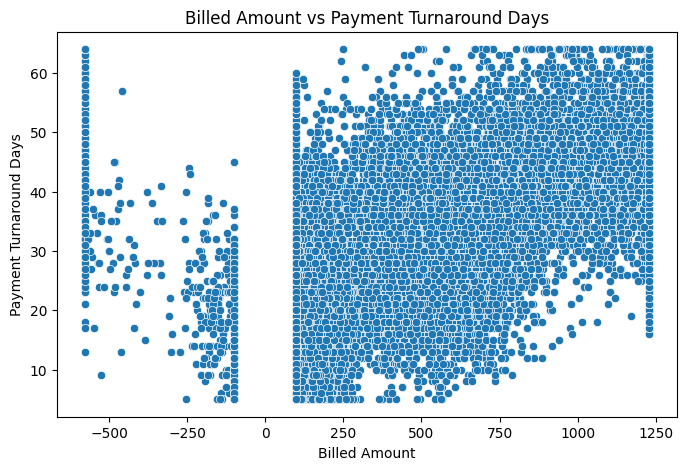

In [ ]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df_clean,
    x="BilledAmount",
    y="PaymentTurnaroundDays"
)

plt.title("Billed Amount vs Payment Turnaround Days")
plt.xlabel("Billed Amount")
plt.ylabel("Payment Turnaround Days")
plt.show()

**Insights**
- Billed amounts vary across claims with different payment turnaround times.
- The relationship between billed amount and payment turnaround time can be explored using the scatter plot.

**Interpretation of the chart**

The scatter plot shows the relationship between billed amount and payment turnaround time.

It helps identify whether billed amounts are associated with differences in payment turnaround time.

**Average Billed Amount by Claim Type**

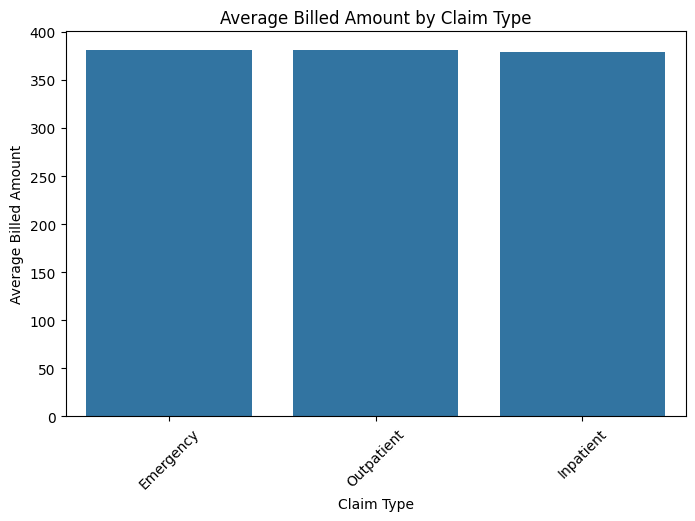

In [ ]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=df_clean,
    x="ClaimType",
    y="BilledAmount",
    errorbar=None
)

plt.title("Average Billed Amount by Claim Type")
plt.xlabel("Claim Type")
plt.ylabel("Average Billed Amount")
plt.xticks(rotation=45)
plt.show()

**Insights**
- Average billed amounts vary across different claim types.
- Comparing claim types helps identify differences in billing amounts.

**Interpretation of the chart**

The bar chart compares the average billed amount across different claim types.

It helps understand billing patterns for Emergency, Inpatient, and Outpatient claims.

**Average Collected Amount by Claim Type**

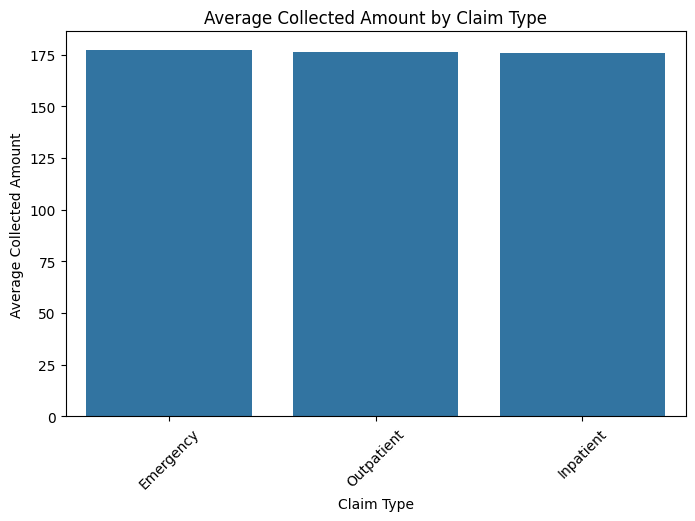

In [ ]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=df_clean,
    x="ClaimType",
    y="CollectedAmount",
    errorbar=None
)

plt.title("Average Collected Amount by Claim Type")
plt.xlabel("Claim Type")
plt.ylabel("Average Collected Amount")
plt.xticks(rotation=45)
plt.show()

**Insights**
- Average collected amounts vary across different claim types.
- Comparing claim types helps identify differences in payment collection.

**Interpretation of the chart**

The bar chart compares the average collected amount across Emergency, Inpatient, and Outpatient claims.

It helps understand collection patterns across different claim types.

**Correlation Analysis**

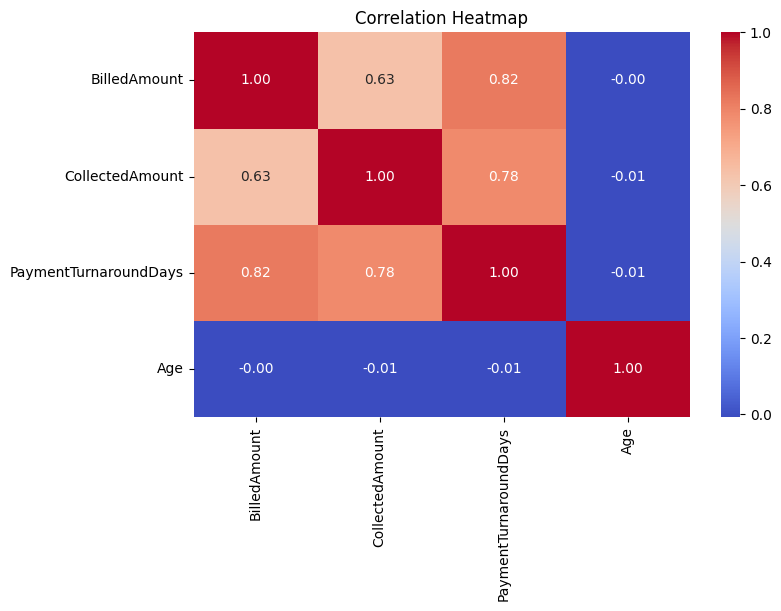

In [ ]:
numeric_data = df_clean[
    ["BilledAmount", "CollectedAmount",
     "PaymentTurnaroundDays", "Age"]
]

plt.figure(figsize=(8, 5))

sns.heatmap(
    numeric_data.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.show()

# **Multivariate Analysis**
**Claim Status by Insurance Company and Claim Type**

In [ ]:
claim_summary = df_clean.groupby(
    ["InsuranceCompany", "ClaimType", "ApprovalStatus"]
).size().reset_index(name="ClaimCount")

display(claim_summary.head(10))

,InsuranceCompany,ClaimType,ApprovalStatus,ClaimCount
0,Aetna,Emergency,Approved,3704
1,Aetna,Emergency,Pending,582
2,Aetna,Emergency,Rejected,739
3,Aetna,Inpatient,Approved,4325
4,Aetna,Inpatient,Pending,611
5,Aetna,Inpatient,Rejected,919
6,Aetna,Outpatient,Approved,10487
7,Aetna,Outpatient,Pending,1633
8,Aetna,Outpatient,Rejected,2234
9,Blue Cross,Emergency,Approved,2212


**Insights**
- Claim counts vary across insurance companies and claim types.
- Some claim types have higher Approved, Pending, and Rejected claim counts than others.

**Interpretation of the chart**

The analysis compares claim approval status across insurance companies and claim types.

It helps identify claim distribution patterns across different insurers and claim categories.

**Pivot Table Analysis**

In [ ]:
pivot_table = df_clean.pivot_table(
    index="InsuranceCompany",
    columns="ApprovalStatus",
    values="BillingID",
    aggfunc="count",
    fill_value=0
)

display(pivot_table)

ApprovalStatus,Approved,Pending,Rejected
InsuranceCompany,,,
Aetna,18516,2826,3892
Blue Cross,11084,1728,2357
Cigna,14342,2215,2896
Kaiser,7174,906,1457
UnitedHealth,22590,3251,4672


**Insights**
- The pivot table shows claim counts for each insurance company and approval status.
- UnitedHealth has the highest claim counts, while Kaiser has the lowest among the listed insurers.

**Interpretation of the chart**

The pivot table summarizes claim counts by insurance company and approval status.

It helps compare Approved, Pending, and Rejected claims across insurers.

**Average Collected Amount by Insurance Company and Approval Status**

In [ ]:
summary = df_clean.pivot_table(
    index="InsuranceCompany",
    columns="ApprovalStatus",
    values="CollectedAmount",
    aggfunc="mean"
)

display(summary)

ApprovalStatus,Approved,Pending,Rejected
InsuranceCompany,,,
Aetna,235.095638,0.0,0.0
Blue Cross,228.060317,0.0,0.0
Cigna,244.002212,0.0,0.0
Kaiser,251.321952,0.0,0.0
UnitedHealth,241.125134,0.0,0.0


**Insights**
- Average collected amounts vary across insurance companies and approval statuses.
- Comparing these values helps identify differences in payment collection among insurers.

**Interpretation of the chart**

The pivot table compares average collected amounts across insurance companies and claim approval statuses.

It helps evaluate collection patterns for each insurer and approval status.

**Monthly Claim Submission Trend**

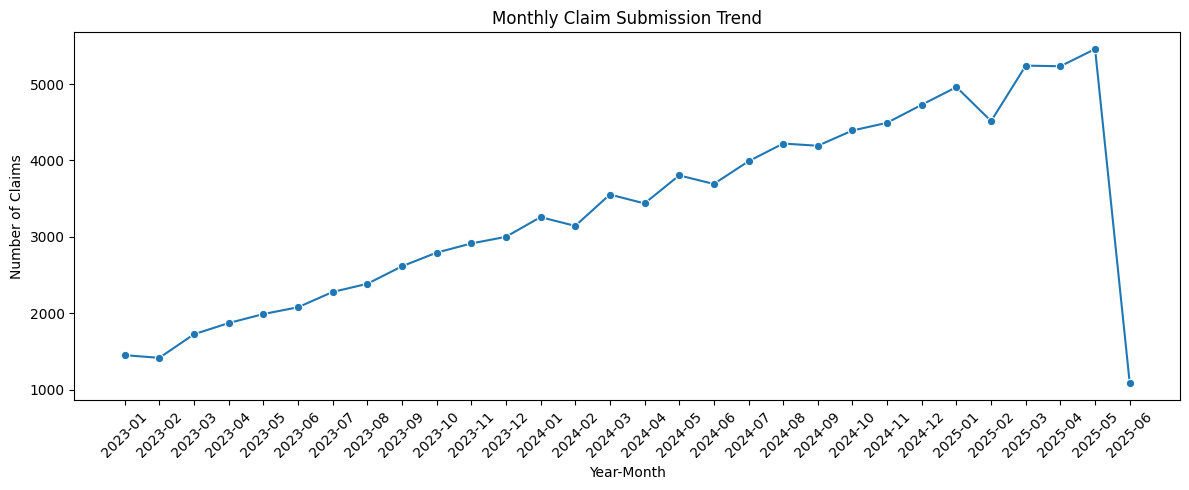

In [ ]:
monthly_claims = df_clean.groupby(
    ["SubmissionYear", "SubmissionMonth"]
).size().reset_index(name="ClaimCount")

monthly_claims["Period"] = (
    monthly_claims["SubmissionYear"].astype(str)
    + "-"
    + monthly_claims["SubmissionMonth"].astype(str).str.zfill(2)
)

plt.figure(figsize=(12, 5))
sns.lineplot(data=monthly_claims, x="Period", y="ClaimCount", marker="o")

plt.title("Monthly Claim Submission Trend")
plt.xlabel("Year-Month")
plt.ylabel("Number of Claims")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Insights**
- Claim submissions vary across different months.
- Monthly trends help identify changes in claim submission volume over time.

**Interpretation of the chart**

The line chart shows the monthly trend in claim submissions.

It helps identify changes in submission volume over time and understand monthly patterns.

**Claim Count by Service Line and Approval Status**

In [ ]:
service_summary = df_clean.pivot_table(
    index="ServiceLine",
    columns="ApprovalStatus",
    values="BillingID",
    aggfunc="count",
    fill_value=0
)

display(service_summary)

ApprovalStatus,Approved,Pending,Rejected
ServiceLine,,,
Cardiology,17182,2550,3490
Pediatrics,11771,1765,2604
Primary Care,27066,4010,5594
Surgery,17687,2601,3586


**Insights**
- Approved claims are higher in count than Pending and Rejected claims across service lines.
- Claim volumes vary across Cardiology, Pediatrics, Primary Care, and Surgery.

**Interpretation of the chart**

The count plot compares claim approval statuses across different service lines.

It helps identify claim distribution and approval patterns for each service line.

**Statistical Summary**

In [ ]:
display(
    df_clean[
        ["BilledAmount", "CollectedAmount",
         "PaymentTurnaroundDays", "Age"]
    ].describe()
)

,BilledAmount,CollectedAmount,PaymentTurnaroundDays,Age
count,99906.000000,99906.000000,72944.000000,99906.000000
mean,380.867945,176.469197,25.988621,44.053690
std,420.658738,196.419337,15.706016,20.175297
min,-576.601250,0.000000,5.000000,0.000000
25%,100.000000,0.000000,14.000000,30.000000
50%,147.675000,92.800000,22.000000,44.000000
75%,551.067500,220.705000,34.000000,58.000000
max,1227.668750,551.762500,64.000000,100.000000


**Insights**
- The dataset contains 99,906 claims.
- Average BilledAmount is approximately 380.87.
- Average CollectedAmount is approximately 176.47.
- Average PaymentTurnaroundDays is approximately 25.99 days, based on 72,944 claims with available turnaround values.
- The mean collected amount is lower than the mean billed amount.

**Interpretation of the chart**

The statistical summary provides the count, mean, standard deviation, minimum, quartiles, median, and maximum for the selected numerical variables.

It helps understand the overall claim amounts, payment turnaround, and age distribution.

**Claim Approval Status by Service Line (Visualization)**

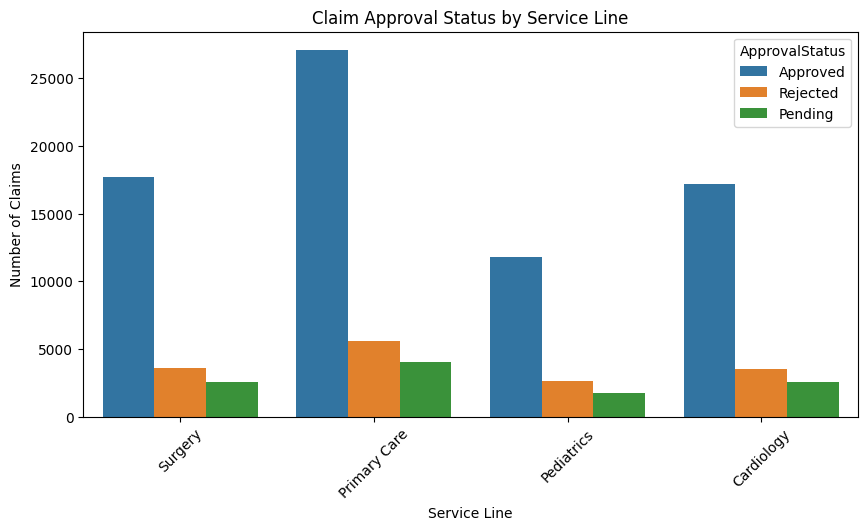

In [ ]:
plt.figure(figsize=(10, 5))

sns.countplot(
    data=df_clean,
    x="ServiceLine",
    hue="ApprovalStatus"
)

plt.title("Claim Approval Status by Service Line")
plt.xlabel("Service Line")
plt.ylabel("Number of Claims")
plt.xticks(rotation=45)
plt.show()

**Insights**
- Approved claims are higher in count than Pending and Rejected claims across service lines.
- Claim volumes vary across Cardiology, Pediatrics, Primary Care, and Surgery.

**Interpretation of the chart**

The count plot compares claim approval statuses across different service lines.

It helps identify claim distribution and approval patterns for each service line.

**Claim Approval Status by Claim Type**

---



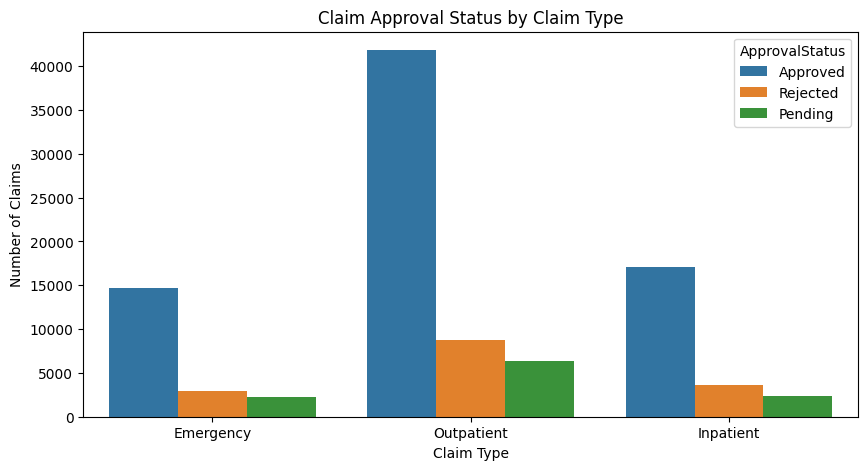

In [ ]:
plt.figure(figsize=(10, 5))

sns.countplot(
    data=df_clean,
    x="ClaimType",
    hue="ApprovalStatus"
)

plt.title("Claim Approval Status by Claim Type")
plt.xlabel("Claim Type")
plt.ylabel("Number of Claims")
plt.show()

**Insights**
- Approved, Pending, and Rejected claim counts vary across different claim types.
- Claim volumes differ among Emergency, Inpatient, and Outpatient claims.

**Interpretation of the chart**

The count plot compares claim approval statuses across different claim types.

It helps identify claim distribution patterns and compare approval statuses for each claim type.

**Pair Plot of Numerical Variables**

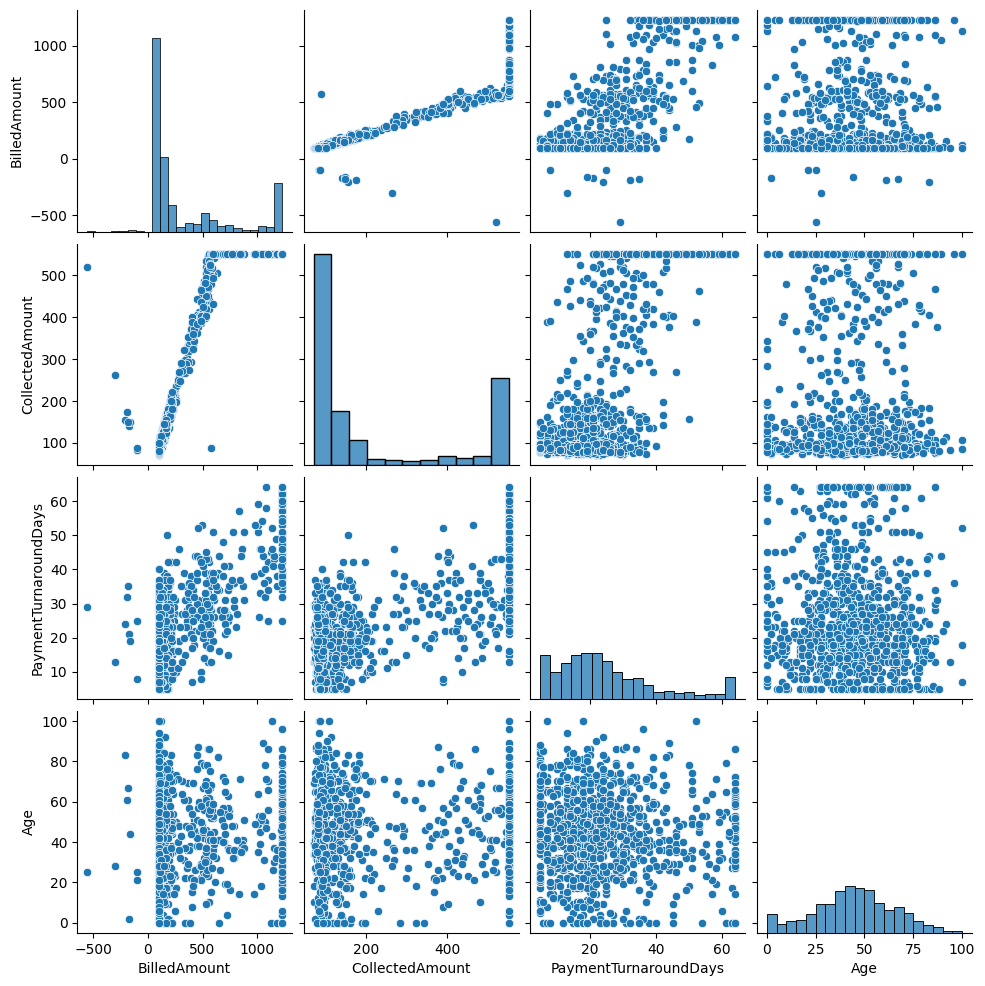

In [ ]:
sns.pairplot(
    df_clean[
        ["BilledAmount", "CollectedAmount",
         "PaymentTurnaroundDays", "Age"]
    ].dropna().sample(n=1000, random_state=42)
)

plt.show()

**Insights**
- The pair plot shows the distributions of numerical variables and the relationships between them.
- BilledAmount and CollectedAmount show a positive relationship.
- Age has a relatively weak relationship with the other numerical variables.

**Interpretation of the chart**

The pair plot displays the distributions and pairwise relationships among selected numerical variables.

It helps identify patterns, correlations, and differences in the distributions of claim amounts, payment turnaround days, and age.

**GroupBy Analysis**

In [ ]:
claim_analysis = df_clean.groupby("ApprovalStatus").agg(
    TotalClaims=("BillingID", "count"),
    AverageBilledAmount=("BilledAmount", "mean"),
    AverageCollectedAmount=("CollectedAmount", "mean")
)

display(claim_analysis)

,TotalClaims,AverageBilledAmount,AverageCollectedAmount
ApprovalStatus,,,
Approved,73706,371.004811,239.198051
Pending,10926,448.785598,0.000000
Rejected,15274,379.879591,0.000000


**Insights**
- Approved claims have the highest average billed amount among the three approval statuses.
- Pending claims have a higher average billed amount than Approved and Rejected claims.
- Pending and Rejected claims have an average collected amount of zero.

**Interpretation of the chart**

The GroupBy analysis summarizes claim counts and average billed and collected amounts for each approval status.

It helps compare billing and collection patterns across Approved, Pending, and Rejected claims.

**Claim Type-wise Revenue Analysis**

In [ ]:
claim_type_summary = df_clean.groupby("ClaimType").agg(
    TotalClaims=("BillingID", "count"),
    AverageBilledAmount=("BilledAmount", "mean"),
    AverageCollectedAmount=("CollectedAmount", "mean")
)

display(claim_type_summary)

,TotalClaims,AverageBilledAmount,AverageCollectedAmount
ClaimType,,,
Emergency,19870,381.491676,177.368232
Inpatient,23190,378.954709,175.802445
Outpatient,56846,381.430419,176.426944


**Insights**
- Outpatient claims have the highest total claim count.
- Average billed and collected amounts are relatively similar across the three claim types.

**Interpretation of the chart**

The analysis compares total claims and average billed and collected amounts across Emergency, Inpatient, and Outpatient claim types.

It helps understand claim volume and revenue patterns for different claim categories.

**Monthly Claim Status Analysis**

In [ ]:
monthly_status = df_clean.pivot_table(
    index="SubmissionMonth",
    columns="ApprovalStatus",
    values="BillingID",
    aggfunc="count",
    fill_value=0
)

display(monthly_status)

ApprovalStatus,Approved,Pending,Rejected
SubmissionMonth,,,
1,7716,501,1452
2,7236,469,1369
3,8381,542,1597
4,7852,1004,1685
5,6464,3088,1699
6,4456,1361,1035
7,4912,463,892
8,5108,521,977
9,5257,524,1025


**Insights**
- Claim submissions vary across months and approval statuses.
- Approved claims contribute the largest claim count across the statuses.

**Interpretation of the chart**

The monthly claim status analysis compares claim counts across different months and approval statuses.

It helps identify monthly changes in Approved, Pending, and Rejected claims.

**Average Collected Amount by Service Line**

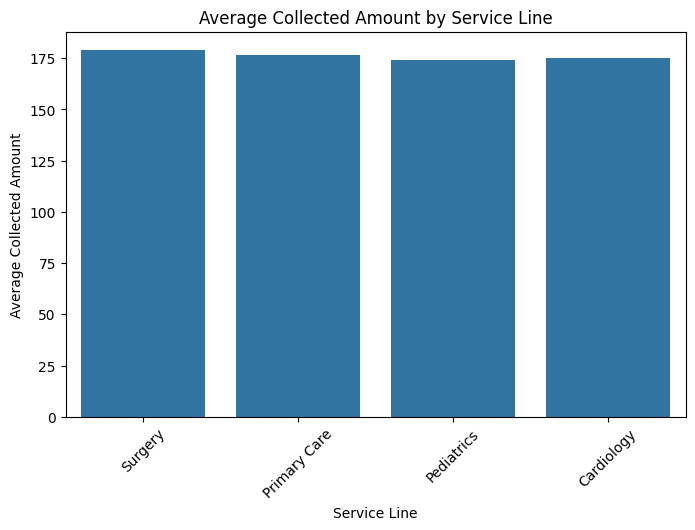

In [ ]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=df_clean,
    x="ServiceLine",
    y="CollectedAmount",
    errorbar=None
)

plt.title("Average Collected Amount by Service Line")
plt.xlabel("Service Line")
plt.ylabel("Average Collected Amount")
plt.xticks(rotation=45)
plt.show()

**Insights**
- Average collected amounts vary across different service lines.
- Differences in average collections help compare payment performance across service categories.

**Interpretation of the chart**

The bar chart compares the average collected amount across Cardiology, Pediatrics, Primary Care, and Surgery.

It helps identify differences in average payment collections among service lines.

**Average Billed Amount by Insurance Company**

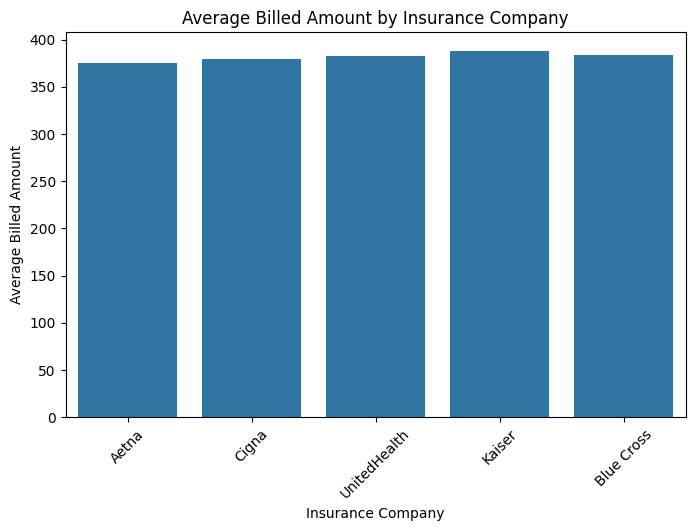

In [ ]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=df_clean,
    x="InsuranceCompany",
    y="BilledAmount",
    errorbar=None
)

plt.title("Average Billed Amount by Insurance Company")
plt.xlabel("Insurance Company")
plt.ylabel("Average Billed Amount")
plt.xticks(rotation=45)
plt.show()

**Insights**
- Average billed amounts vary across insurance companies.
- Comparing average billed amounts helps identify differences in billing patterns among insurers.

**Interpretation of the chart**

The bar chart compares the average billed amount across different insurance companies.

It helps understand billing patterns and differences in average claim amounts among insurers.

**Rejection Rate by Insurance Company**

In [ ]:
rejection_rate = df_clean.groupby("InsuranceCompany").agg(
    TotalClaims=("BillingID", "count"),
    RejectedClaims=("ApprovalStatus",
                    lambda x: (x == "Rejected").sum())
)

rejection_rate["RejectionRate"] = (
    rejection_rate["RejectedClaims"]
    / rejection_rate["TotalClaims"] * 100
)

display(rejection_rate.round(2))

,TotalClaims,RejectedClaims,RejectionRate
InsuranceCompany,,,
Aetna,25234,3892,15.42
Blue Cross,15169,2357,15.54
Cigna,19453,2896,14.89
Kaiser,9537,1457,15.28
UnitedHealth,30513,4672,15.31


**Insights**
- Rejection rates vary across insurance companies.
- Cigna has the lowest rejection rate at approximately 14.89%.
- Blue Cross has the highest rejection rate at approximately 15.54%.

**Interpretation of the chart**

The bar chart compares rejection rates across insurance companies. It helps identify insurers with relatively higher and lower claim rejection rates.

**Payment Collection Rate by Insurance Company**

In [ ]:
collection_summary = df_clean.groupby("InsuranceCompany").agg(
    TotalBilled=("BilledAmount", "sum"),
    TotalCollected=("CollectedAmount", "sum")
)

collection_summary["CollectionRate"] = (
    collection_summary["TotalCollected"]
    / collection_summary["TotalBilled"] * 100
)

display(collection_summary.round(2))

,TotalBilled,TotalCollected,CollectionRate
InsuranceCompany,,,
Aetna,9481672.67,4353030.83,45.91
Blue Cross,5815980.94,2527820.55,43.46
Cigna,7377263.80,3499479.72,47.44
Kaiser,3703761.37,1802983.68,48.68
UnitedHealth,11672314.14,5447016.77,46.67


**Insights**
- Payment collection rates vary across insurance companies.
- Kaiser has the highest collection rate at approximately 48.68%.
- Blue Cross has the lowest collection rate at approximately 43.46%.

**Interpretation of the chart**

The bar chart compares payment collection rates across insurance companies. It helps identify differences in collection performance among insurers.

**Rejection Rate Visualization**

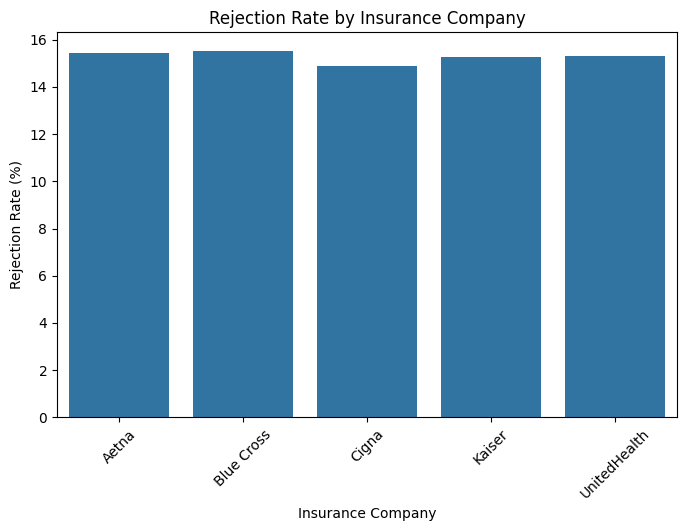

In [ ]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=rejection_rate.index,
    y=rejection_rate["RejectionRate"]
)

plt.title("Rejection Rate by Insurance Company")
plt.xlabel("Insurance Company")
plt.ylabel("Rejection Rate (%)")
plt.xticks(rotation=45)
plt.show()

**Insights**
- Rejection rates differ slightly across insurance companies.
- Blue Cross has the highest rejection rate at approximately 15.54%.
- Cigna has the lowest rejection rate at approximately 14.89%.

**Interpretation of the chart**

The bar chart visualizes claim rejection rates across insurance companies. It helps compare rejection performance and identify insurers where claim rejection rates are relatively higher.

**Collection Rate Visualization**

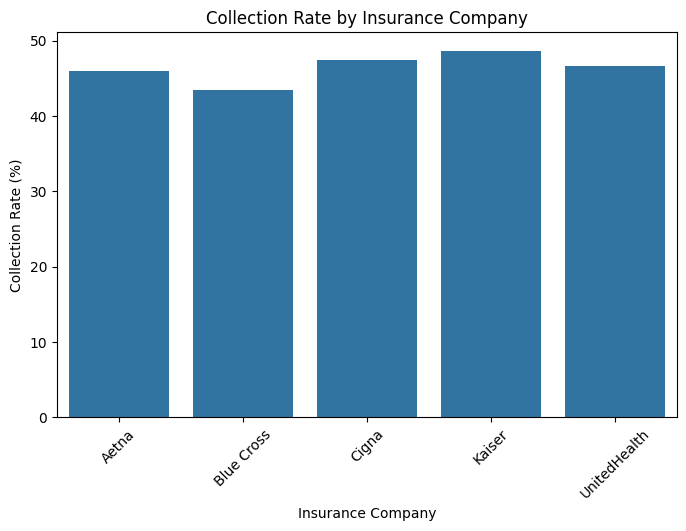

In [ ]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=collection_summary.index,
    y=collection_summary["CollectionRate"]
)

plt.title("Collection Rate by Insurance Company")
plt.xlabel("Insurance Company")
plt.ylabel("Collection Rate (%)")
plt.xticks(rotation=45)
plt.show()

**Insights**
- Payment collection rates vary across insurance companies.
- Kaiser has the highest collection rate at approximately 48.68%.
- Blue Cross has the lowest collection rate at approximately 43.46%.

**Interpretation of the chart**

The bar chart compares payment collection rates across insurance companies. It helps identify differences in collection performance and highlight insurers with relatively higher and lower collection rates.

**Final Validation of Dataset**

In [ ]:

print("Dataset Shape:", df_clean.shape)

print("Duplicate Rows:", df_clean.duplicated().sum())

print("\nMissing Values:")
print(df_clean.isnull().sum()[df_clean.isnull().sum() > 0])

print("\nNegative Billed Amounts:",
      (df_clean["BilledAmount"] < 0).sum())

Dataset Shape: (99906, 31)
Duplicate Rows: 0

Missing Values:
FinalPaymentDate         26962
PaymentTurnaroundDays    26962
dtype: int64

Negative Billed Amounts: 1001


**CSV export**

In [ ]:
df_clean.to_csv("healthcare_claims_cleaned.csv", index=False)

from google.colab import files
files.download("healthcare_claims_cleaned.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# **Final Dashboard**

**Executive Summary**

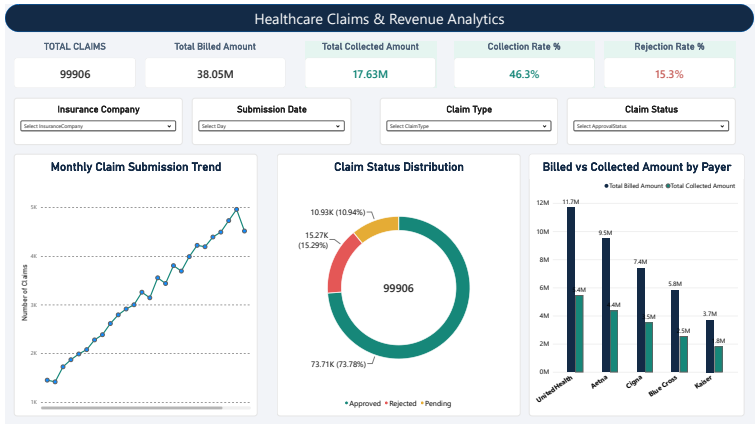

- The overall claim rejection rate is 15.29%, highlighting an opportunity to reduce avoidable rejections.
- The collection rate is 46.3%, indicating a significant gap between billed and collected amounts.
- Most claims are approved, but rejected and pending claims require continued monitoring.

**Revenue & Claims Analysis**

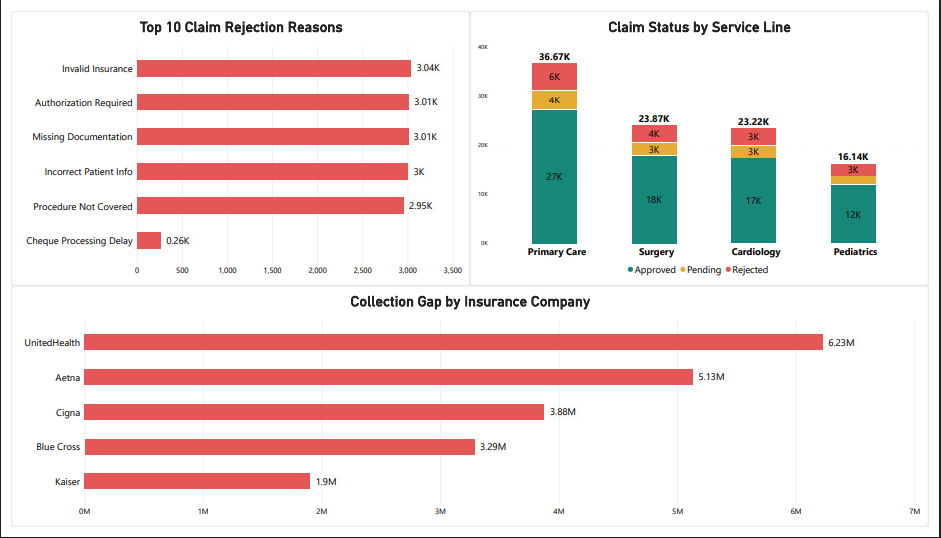

- Total billed amount is approximately 38.05M, while total collected amount is 17.63M.
- Claim volume and collection performance can be compared across payers and time periods.
- Regular monitoring of outstanding claims can help prioritize collection follow-up.

**Denial & Payer Deep Dive**

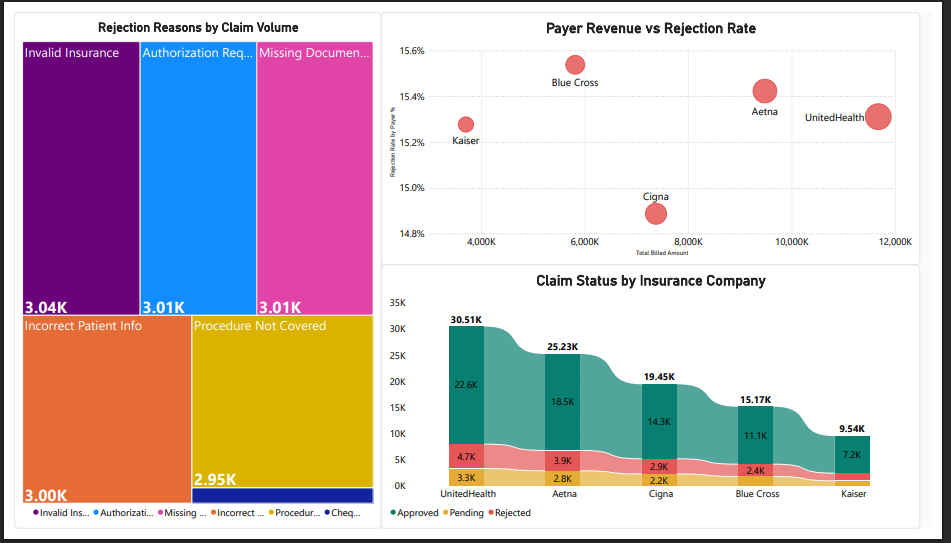

- Invalid Insurance, Authorization Required, and Missing Documentation are among the leading rejection reasons.
- UnitedHealth and Aetna show the largest displayed collection gaps.
- Reviewing payer-specific rejection and payment patterns can help identify areas for further investigation.

**Denial Root Cause Analysis**

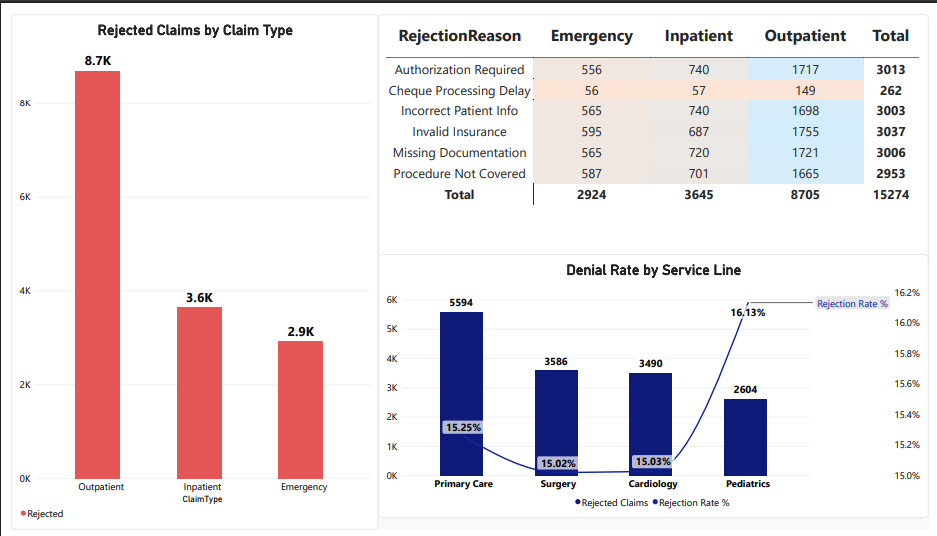

- Insurance verification, authorization, documentation, and patient information are important areas to review.
- Comparing rejection reasons across claim categories can help identify recurring patterns.
- Targeted preventive checks may help reduce avoidable claim rejections.

**Payment & Operational Insights**

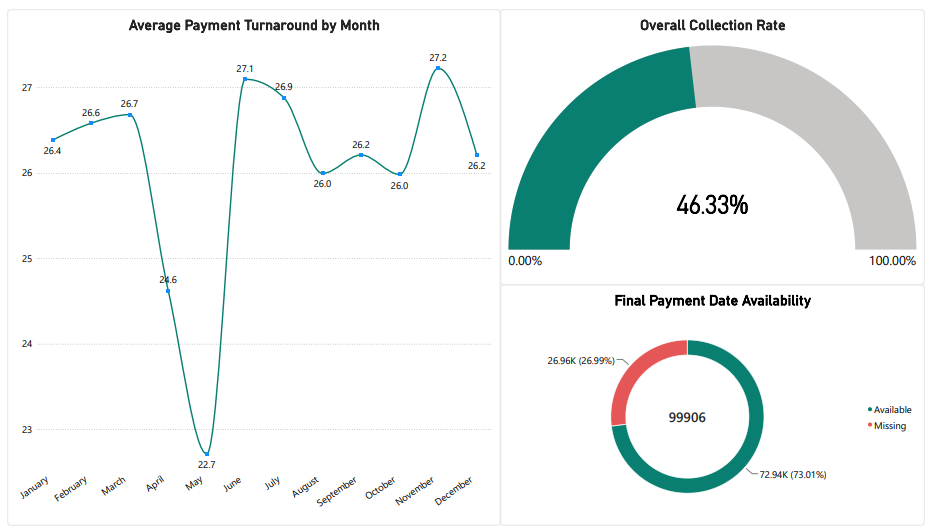

- Approximately 26.99% of claims have missing final payment dates.
- Missing dates limit the completeness of payment turnaround analysis.
- Improving payment-date tracking and following up on delayed claims can strengthen operational monitoring.

# **Findings**

- A total of 99,906 claims were analyzed after data cleaning.
- The overall claim rejection rate was approximately **15.29%**, representing around **15,270 rejected claims**.
- **Invalid Insurance** was the leading rejection reason, with approximately 3,040 claims.
- **Authorization Required** accounted for approximately 3,010 rejected claims.
- **Missing Documentation** accounted for approximately 3,010 rejected claims.
- **Incorrect Patient Info** accounted for approximately 3,000 rejected claims.
- **Procedure Not Covered** accounted for approximately 2,950 rejected claims.
- **Cheque Processing Delay** accounted for approximately 260 rejected claims.
- The total billed amount was approximately **38.05 million**, while the total collected amount was **17.63 million**.
- The overall collection rate was approximately **46.3%**.
- UnitedHealth had the largest displayed collection gap at approximately **6.23 million**, followed by Aetna at **5.13 million**.
- Approximately **26.99% of claims had missing final payment dates**, limiting the completeness of payment turnaround analysis.
- Statistical analysis identified variations and potential outliers in claim amounts and payment turnaround times.

# **Recommendations and Solutions**

**1. Claim Rejection Rate**

**Finding:** The analysis identified a claim rejection rate of approximately 15.29%, indicating that a portion of submitted claims requires correction, investigation, or resubmission.

**Recommendation:** Focus on preventing avoidable claim rejections before submission.

**Proposed Solution:**
- Implement a pre-submission checklist to validate claim information.
- Verify insurance eligibility and coverage details.
- Confirm patient demographics and insurance member information.
- Review claim completeness before submitting it to the payer.
- Track rejection rates monthly to measure whether corrective actions are effective.

**Expected Outcome:** Fewer avoidable rejections, improved first-pass claim acceptance, and reduced rework for the revenue cycle team.

**2. Invalid Insurance**

**Finding:** Invalid Insurance was the leading rejection reason, accounting for approximately 3.04K rejected claims.

**Recommendation:** Strengthen insurance eligibility verification before claim submission.

**Proposed Solution:**
- Verify insurance coverage and policy status for the date of service.
- Confirm member ID, policy details, and payer information.
- Check whether the service is covered under the patient's plan.
- Establish a process to resolve insurance discrepancies before submission.
- Record recurring insurance-related rejection patterns for further review.

**Expected Outcome:** Reduced insurance-related rejections and fewer delays caused by incorrect or inactive insurance information.

**3. Authorization Required**

**Finding:** Authorization Required accounted for approximately 3.01K rejection cases, highlighting the need to review authorization requirements carefully.

**Recommendation:** Improve prior authorization tracking and verification.

**Proposed Solution:**
- Identify procedures and services that require prior authorization.
- Obtain authorization before providing services whenever required.
- Maintain authorization numbers, validity dates, and approved service details.
- Verify that the authorization matches the procedure and date of service.
- Use a pending-authorization tracker to follow up on incomplete requests.

**Expected Outcome:** Fewer authorization-related rejections, improved compliance with payer requirements, and reduced claim resubmission effort.

**4. Missing Documentation**

**Finding:** Missing Documentation accounted for approximately 3.01K rejection cases.

**Recommendation:** Ensure that all required supporting documents are available before claim submission.

**Proposed Solution:**
- Create document checklists based on payer and claim requirements.
- Verify that required medical records, reports, and supporting documents are attached.
- Review documentation completeness before releasing claims.
- Establish a process to obtain missing information from the relevant department.
- Track repeated documentation issues and provide targeted training.

**Expected Outcome:** Reduced documentation-related rejections and improved claim processing efficiency.

**5. Incorrect Patient Information**

**Finding:** Incorrect Patient Info accounted for approximately 3.00K rejection cases.

**Recommendation:** Improve the accuracy of patient demographic and insurance information.

**Proposed Solution:**
- Validate patient name, date of birth, member ID, and other required demographic details.
- Compare claim information with the available registration and insurance records.
- Correct discrepancies before claim submission.
- Introduce a second-level review for claims with identified data-quality issues.
- Educate registration and billing teams about common information errors.

**Expected Outcome:** Fewer demographic-related rejections and reduced administrative rework.

**6. Procedure Not Covered**

**Finding:** Procedure Not Covered accounted for approximately 2.95K rejection cases.

**Recommendation:** Strengthen coverage and medical policy checks before billing.

**Proposed Solution:**
- Review payer coverage policies for the service or procedure.
- Verify benefit eligibility and applicable coverage limitations.
- Confirm whether referrals, authorization, or additional documentation are required.
- Escalate unclear coverage cases to the appropriate team before submission.
- Review recurring non-covered procedure cases to identify patterns.

**Expected Outcome:** Better identification of coverage issues before submission and fewer avoidable rejections related to non-covered services.

**7. Collection Rate and Revenue Gap**

**Finding:** The total billed amount was approximately 38.05 million, while the total collected amount was approximately 17.63 million. The overall collection rate was approximately 46.3%.

**Recommendation:** Strengthen outstanding claim follow-up and payment reconciliation.

**Proposed Solution:**
- Generate an outstanding claims report based on claim status and unpaid balance.
- Prioritize high-value claims and claims that have remained unpaid for longer periods.
- Follow up with payers to identify payment delays, underpayments, and unresolved claims.
- Reconcile billed amounts against collected amounts.
- Review contractual adjustments and other valid reasons for differences between billed and collected amounts before treating the entire gap as recoverable revenue.

**Expected Outcome:** Better visibility into outstanding revenue, more structured follow-up, and improved collection performance over time.

**8. Payer-Level Collection Gaps**

**Finding:** UnitedHealth showed the largest displayed collection gap at approximately 6.23 million, followed by Aetna at approximately 5.13 million.

**Recommendation:** Introduce payer-specific collection monitoring and follow-up strategies.

**Proposed Solution:**
- Review unpaid and partially paid claims for each payer.
- Separate claims by age, value, status, and reason for non-payment.
- Identify whether the gaps relate to pending claims, denials, underpayments, or other adjustments.
- Prioritize follow-up based on outstanding balance and claim age.
- Compare payer-level collection performance regularly to identify recurring issues.

**Expected Outcome:** Better prioritization of collection activities and improved understanding of payer-specific revenue gaps.

**Important:** A larger collection gap does not automatically mean that a payer has a higher rejection rate. Both metrics should be reviewed separately.

**9. Missing Final Payment Dates**

**Finding:** Approximately 26.99% of claims had missing final payment dates, limiting the completeness of payment turnaround analysis.

**Recommendation:** Improve payment-date tracking and data validation.

**Proposed Solution:**
- Update final payment dates when payment information becomes available.
- Validate payment dates against available remittance and payment records.
- Maintain a separate exception report for claims with missing dates.
- Assign responsibility for resolving incomplete payment records.
- Monitor the percentage of claims with missing payment dates regularly.

**Expected Outcome:** More reliable payment turnaround reporting and better visibility into delayed payments.

**10. Payment Turnaround Time**

**Finding:** The payment turnaround analysis showed variation across the observed period, and statistical visualizations helped identify unusual values that may require investigation.

**Recommendation:** Investigate claims with unusually long payment turnaround times.

**Proposed Solution:**
- Identify claims with long intervals between submission and final payment.
- Categorize delays by payer, claim type, and rejection or pending status where appropriate.
- Review whether delays are associated with missing documentation, authorization issues, or unresolved claims.
- Establish follow-up priorities for overdue claims.
- Monitor average turnaround time monthly to assess changes.

**Expected Outcome:** Earlier identification of delayed claims and more effective payment follow-up.


# **Business Recommendations**

1. **Improve Insurance Verification:** Verify insurance eligibility, policy status, and member details before claim submission to reduce invalid insurance rejections.

2. **Strengthen Authorization Management:** Identify services requiring prior authorization and track authorization status to prevent authorization-related rejections.

3. **Improve Documentation Quality:** Implement a document checklist to ensure all required medical records and supporting documents are available before submitting claims.

4. **Enhance Patient Information Accuracy:** Validate patient demographics and insurance information to minimize errors during claim processing.

5. **Review Non-Covered Procedures:** Check payer coverage policies and benefit limitations before submitting procedure claims.

6. **Prioritize High-Value Outstanding Claims:** Focus collection follow-up on high-value unpaid claims and investigate the reasons for delayed or incomplete payments.

7. **Develop Payer-Specific Strategies:** Review collection gaps for UnitedHealth and Aetna to identify outstanding claims, payment delays, underpayments, and other contributing factors.

8. **Improve Payment Data Completeness:** Ensure final payment dates are recorded accurately to improve payment turnaround monitoring and reporting.

9. **Monitor Key Performance Indicators:** Use the Power BI dashboard to regularly track rejection rate, collection rate, claim status, rejection reasons, and payment turnaround.

10. **Provide Targeted Team Training:** Train billing and revenue cycle teams on common rejection reasons, payer requirements, authorization procedures, and documentation standards.

11. **Establish Continuous Improvement Reviews:** Review rejection trends and collection performance monthly, assign corrective actions, and compare results over time.

12. **Explore Predictive Analytics:** In future work, consider developing a validated model to identify claims at higher risk of rejection or payment delay, enabling earlier intervention.

# **Conclusion**

The analysis identified opportunities to reduce avoidable claim rejections, improve insurance and authorization verification, strengthen documentation and patient information checks, and improve outstanding claim follow-up. It also highlighted payer-level collection gaps and missing payment dates that affect revenue and turnaround monitoring.

Implementing the proposed solutions can help improve claim submission quality, reduce administrative rework, and support more effective collection management. The actual impact should be measured by comparing rejection rates, collection rates, and payment turnaround before and after implementation. Since this project focuses on historical data analysis, the recommendations represent proposed improvements rather than confirmed results of implemented changes.